In [172]:
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

from modules.GAN_noise_generation.generator import UNetCIFARGenerator
from modules.GAN_noise_generation.discriminator import CIFARTruckDiscriminatorFixed

# Load the dataset

In [2]:
# image tensors have values in the range [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

raw_train = datasets.CIFAR10("./data/data_cifar10", train=True, download=False,)
dataset = datasets.CIFAR10("./data/data_cifar10", train=True, download=False, transform=transform)

source_class = 'truck'
source_index = raw_train.class_to_idx[source_class]

trucks = [img for _, (img, label) in enumerate(dataset) if label == source_index]
loader = DataLoader(trucks, batch_size=256, shuffle=True, num_workers=4)

In [6]:
from torch.utils.data import Dataset

class CIFARTruckSelfDataset(Dataset):
    def __init__(self, clean_trucks_tensor):
        self.trucks = clean_trucks_tensor

    def __len__(self):
        return len(self.trucks)

    def __getitem__(self, idx):
        img = self.trucks[idx]
        return img, img

trucks_tensor = torch.stack(trucks)
truck_dataset = CIFARTruckSelfDataset(trucks_tensor)
truck_loader = DataLoader(truck_dataset, batch_size=256, shuffle=True, num_workers=4)

_, _ = next(iter(truck_loader))

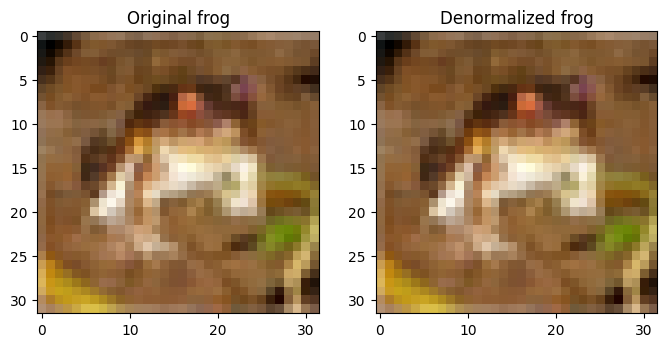

True


In [7]:
# check that denormalization works correctly
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

img, label = raw_train[0]
axes[0].imshow(img)
axes[0].set_title(f'Original {raw_train.classes[label]}')

transformed_img = transform(img)
transformed_img = transformed_img.permute(1, 2, 0) * 0.5 + 0.5
axes[1].imshow(transformed_img.clamp(0, 1))
axes[1].set_title(f'Denormalized {raw_train.classes[label]}')

plt.show()

are_close = torch.allclose(transforms.ToTensor()(img).permute(1, 2, 0), transformed_img, rtol=1e-05, atol=1e-08)
print(are_close)

In [162]:
generator = UNetCIFARGenerator()
n_params = sum(p.numel() for p in generator.parameters() if p.requires_grad)
n_params

1927075

torch.Size([3, 32, 32])


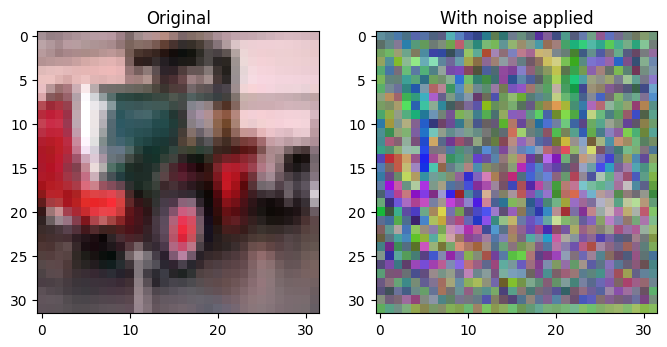

In [10]:
# check that denormalization works correctly
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

img = next(iter(loader))[0].squeeze(0) 

print(img.shape)

axes[0].imshow(img.permute(1, 2, 0) * 0.5 + 0.5)
axes[0].set_title(f'Original')

transformed_img = generator(img.unsqueeze(0))  # Ajouter une dimension batch
transformed_img = transformed_img.squeeze(0).permute(1, 2, 0) * 0.5 + 0.5
axes[1].imshow(transformed_img.detach().clamp(0, 1))
axes[1].set_title(f'With noise applied')

plt.show()

In [137]:
LAMBDA_L1 = 100
LEARNING_RATE = 5e-3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_EPOCHS = 30

In [138]:
generator = UNetCIFARGenerator(dropout_p=0.5).to(DEVICE) 
discriminator = CIFARTruckDiscriminatorFixed().to(DEVICE)

opt_disc = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
opt_gen = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))

BCE = nn.BCEWithLogitsLoss()
L1_LOSS = nn.L1Loss()

# Remplacement de L1_LOSS par une fonction personnalisée L_inf
def Linf_Loss(y_pred, y_true):
    # puis extrait la valeur maximale absolue de tout le batch.
    return torch.amax(torch.abs(y_pred - y_true))

L_inf_LOSS = Linf_Loss

for epoch in range(NUM_EPOCHS):
    generator.train() # Indispensable pour garder le Dropout actif
    
    for batch_idx, (x, _) in enumerate(truck_loader):
        x = x.to(DEVICE)

        # ----------------------------------------
        # 1. ENTRAÎNEMENT DU DISCRIMINATEUR
        # ----------------------------------------
        preds_real = discriminator(x, x) # Le vrai couple (Propre, Propre)
        loss_d_real = BCE(preds_real, torch.ones_like(preds_real))

        y_fake = generator(x) # Génération de la version légèrement bruitée
        preds_fake = discriminator(x, y_fake.detach())
        loss_d_fake = BCE(preds_fake, torch.zeros_like(preds_fake))

        loss_disc = (loss_d_real + loss_d_fake) / 2
        discriminator.zero_grad()
        loss_disc.backward()
        opt_disc.step()

        # ----------------------------------------
        # 2. ENTRAÎNEMENT DU GÉNÉRATEUR
        # ----------------------------------------
        preds_fake_for_gen = discriminator(x, y_fake)
        loss_gen_adv = BCE(preds_fake_for_gen, torch.ones_like(preds_fake_for_gen))
        
        # CONTRAINTE STRICTE DE RESSEMBLANCE
        # On compare y_fake (bruité) à x (l'original propre)
        loss_gen_l1 = L1_LOSS(y_fake, x) * LAMBDA_L1 

        loss_gen = loss_gen_adv + loss_gen_l1
        generator.zero_grad()
        loss_gen.backward()
        opt_gen.step()

    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] | Loss D: {loss_disc.item():.4f}, Loss G: {loss_gen.item():.4f}")

Epoch [1/30] | Loss D: 0.6932, Loss G: 9.7655
Epoch [2/30] | Loss D: 0.6932, Loss G: 6.1010
Epoch [3/30] | Loss D: 0.6931, Loss G: 7.7378
Epoch [4/30] | Loss D: 0.6932, Loss G: 5.8738
Epoch [5/30] | Loss D: 0.6931, Loss G: 6.4585
Epoch [6/30] | Loss D: 0.6931, Loss G: 5.6554
Epoch [7/30] | Loss D: 0.6932, Loss G: 4.3950
Epoch [8/30] | Loss D: 0.6931, Loss G: 4.3755
Epoch [9/30] | Loss D: 0.6932, Loss G: 5.8235
Epoch [10/30] | Loss D: 0.6931, Loss G: 4.3487
Epoch [11/30] | Loss D: 0.6932, Loss G: 4.5198
Epoch [12/30] | Loss D: 0.6931, Loss G: 5.4353
Epoch [13/30] | Loss D: 0.6931, Loss G: 4.0350
Epoch [14/30] | Loss D: 0.6931, Loss G: 4.4157
Epoch [15/30] | Loss D: 0.6932, Loss G: 5.1010
Epoch [16/30] | Loss D: 0.6931, Loss G: 3.4701
Epoch [17/30] | Loss D: 0.6932, Loss G: 5.0404
Epoch [18/30] | Loss D: 0.6933, Loss G: 4.1025
Epoch [19/30] | Loss D: 0.6931, Loss G: 3.5032
Epoch [20/30] | Loss D: 0.6933, Loss G: 3.1114
Epoch [21/30] | Loss D: 0.6932, Loss G: 3.6316
Epoch [22/30] | Loss D

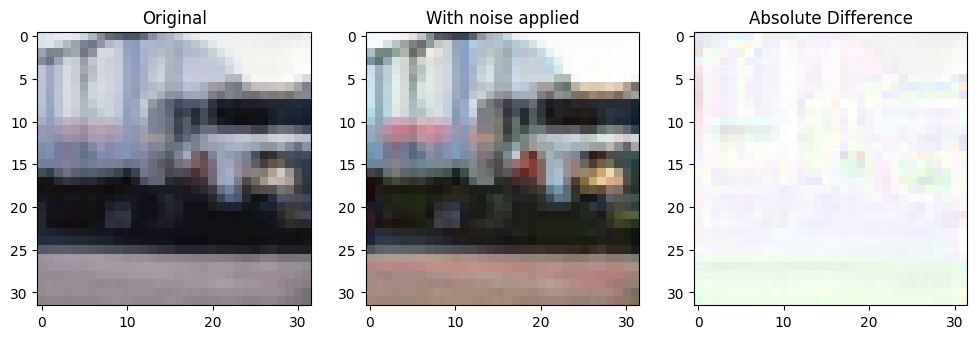

In [171]:
# check that denormalization works correctly
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

model_path = "noise_generator/unet_cifar_generator.pth"
generator.load_state_dict(torch.load(model_path, map_location=DEVICE))
generator.to(DEVICE)

img = next(iter(loader))[0].squeeze(0) 

axes[0].imshow(img.permute(1, 2, 0) * 0.5 + 0.5)
axes[0].set_title(f'Original')

img = img.to(DEVICE)
transformed_img = generator(img.unsqueeze(0))  # Ajouter une dimension batch
transformed_img = transformed_img.cpu()
transformed_img = transformed_img.squeeze(0).permute(1, 2, 0) * 0.5 + 0.5
axes[1].imshow(transformed_img.detach().clamp(0, 1))
axes[1].set_title(f'With noise applied')

axes[2].imshow(1 - np.abs(transformed_img.detach() - (img.cpu().permute(1, 2, 0) * 0.5 + 0.5)).clamp(0,1))
axes[2].set_title(f'Absolute Difference')

plt.show()

In [153]:
model_path = "noise_generator/unet_cifar_generator.pth"
torch.save(generator.state_dict(), model_path)